<img src="https://github.com/JuliaLang/julia/raw/master/doc/src/assets/logo.svg" width="72" alt="Julia logo" /> <img src="https://avatars.githubusercontent.com/u/7346142?s=200&v=4" width="72" alt="KernelAbstractions logo" />

In [ ]:
# Pick your hardware: :CUDA (NVIDIA), :AMDGPU (AMD), :Metal (Apple), or :CPU
DEV = :CUDA


# 1. Setup

The setup is the same as in the GPU introduction, which explains it. The cells below activate the project environment, install and load the packages, and select the backend; set `DEV` in the **second cell** (run it before `Pkg.add`) to match your hardware.

In [34]:
using Pkg
Pkg.activate(@__DIR__)

  Activating project at `c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks`


In [ ]:
packages = ["BenchmarkTools", "KernelAbstractions", "Plots"]
if DEV != :CPU
    push!(packages, string(DEV))
end
Pkg.add(packages)


In [ ]:
using BenchmarkTools, LinearAlgebra, KernelAbstractions, Plots


In [37]:
Pkg.status()

Status `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\Project.toml`
  [21141c5a] AMDGPU v2.11.0
  [6e4b80f9] BenchmarkTools v1.8.0
  [052768ef] CUDA v6.5.0
  [63c18a36] KernelAbstractions v0.10.4
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7


## 1.1. Selecting a backend

Each vendor has its own Julia package (CUDA.jl, AMDGPU.jl, Metal.jl). `Pkg.add` uses `string(DEV)` when `DEV != :CPU`. The cell below runs `@eval using $(DEV)` and sets `ArrayKA` and `Backend`.


In [ ]:
if DEV != :CPU
    @eval using $(DEV)
end

if DEV == :CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :CUDA, :AMDGPU, :Metal, or :CPU.")
end


# 2. Transpose and matrix multiplication

We will examine a transpose kernel and you will write a matmul (matrix-multiplication or GEMM) kernel.

## 2.1. Transpose

We use `Float32` throughout. Single precision is much faster than `Float64` on GPUs, by a factor of 32 to 64 on consumer cards, and Apple GPUs do not support `Float64` at all.

In [39]:
matrix_size = 1024
A = rand(Float32, matrix_size, matrix_size)
B = rand(Float32, matrix_size, matrix_size)
C = zeros(Float32, matrix_size, matrix_size)

A

1024×1024 Matrix{Float32}:
 0.398964   0.813619  0.208787   …  0.0977883  0.0371032  0.48728
 0.181864   0.460602  0.677865      0.987559   0.460466   0.783545
 0.0261927  0.543478  0.645915      0.967614   0.0839122  0.908511
 0.587476   0.703884  0.54708       0.685952   0.669637   0.326943
 0.157129   0.156551  0.643094      0.0339161  0.0286552  0.292982
 0.645736   0.489094  0.345173   …  0.865717   0.39695    0.578625
 0.355523   0.647092  0.75424       0.918635   0.37882    0.484544
 0.9262     0.469889  0.753238      0.360099   0.364919   0.371959
 0.673543   0.956101  0.075631      0.0780212  0.428213   0.669622
 0.849038   0.168042  0.376634      0.46745    0.439494   0.78025
 ⋮                               ⋱                        
 0.808391   0.97153   0.322014   …  0.864321   0.52316    0.186153
 0.875903   0.255179  0.0112019     0.578999   0.0134739  0.354165
 0.821723   0.289195  0.196586      0.0804173  0.749689   0.0985179
 0.0935776  0.996351  0.366259      0.030329

### 2.1.1. On the CPU

The transpose `AT` of `A` satisfies `AT[j, i] = A[i, j]`.

We use explicit names so our code is easy to tell apart from Julia's built-ins: `my_transpose_cpu!` (nested loops on the CPU), `my_naive_transpose_gpu_kernel!` / `my_naive_transpose_gpu!` (one work item per element on the device), and later `my_tiled_transpose_gpu_kernel!`. Correctness checks still use lazy `transpose(A)`; fast library paths use `permutedims!`. The same `my_<what>_<cpu|gpu>_…` naming is used in the Gray–Scott and GPU introduction notebooks.

In [40]:
AT = zeros(Float32, matrix_size, matrix_size)

function my_transpose_cpu!(AT, A)
    for j in 1:size(A, 2)
        for i in 1:size(A, 1)
            AT[j, i] = A[i, j]
        end
    end
end

my_transpose_cpu!(AT, A)
AT == transpose(A)

true

`permutedims!(dest, src, (2, 1))` writes the transpose into an existing array. The permutation `(2, 1)` swaps the two dimensions. It is the built-in transpose, as `*` is the built-in product. `transpose(A)` itself does not copy; it only swaps the indexing.

In [41]:
YT = zeros(Float32, matrix_size, matrix_size)
permutedims!(YT, A, (2, 1))
YT == transpose(A)

true

### 2.1.2. On the device

Copy `A` to the device, as for the vectors in the GPU introduction:

In [42]:
DA = allocate(Backend, Float32, matrix_size, matrix_size)
copyto!(DA, A)

DA

1024×1024 CuArray{Float32, 2, CUDACore.DeviceMemory}:
 0.398964   0.813619  0.208787   …  0.0977883  0.0371032  0.48728
 0.181864   0.460602  0.677865      0.987559   0.460466   0.783545
 0.0261927  0.543478  0.645915      0.967614   0.0839122  0.908511
 0.587476   0.703884  0.54708       0.685952   0.669637   0.326943
 0.157129   0.156551  0.643094      0.0339161  0.0286552  0.292982
 0.645736   0.489094  0.345173   …  0.865717   0.39695    0.578625
 0.355523   0.647092  0.75424       0.918635   0.37882    0.484544
 0.9262     0.469889  0.753238      0.360099   0.364919   0.371959
 0.673543   0.956101  0.075631      0.0780212  0.428213   0.669622
 0.849038   0.168042  0.376634      0.46745    0.439494   0.78025
 ⋮                               ⋱                        
 0.808391   0.97153   0.322014   …  0.864321   0.52316    0.186153
 0.875903   0.255179  0.0112019     0.578999   0.0134739  0.354165
 0.821723   0.289195  0.196586      0.0804173  0.749689   0.0985179
 0.0935776  0.996

In [43]:
DAt = KernelAbstractions.zeros(Backend, Float32, matrix_size, matrix_size)
permutedims!(DAt, DA, (2, 1))
KernelAbstractions.synchronize(Backend)

Array(DAt) == transpose(A)

true

### 2.1.3. `my_naive_transpose_gpu_kernel!`

For matrices, `@index(Global, NTuple)` returns a pair `(i, j)` instead of a single index. Without `NTuple`, the global index stays linear rather than a row and column. With `ndrange = size(A)`, KernelAbstractions launches one work item per matrix element; a 2D workgroup shape unpacks the linear work-item range into `(i, j)`. That 2D view is a convenience for writing matrix indices—the hardware still uses linear thread ids and linear memory.

Each work item performs one assignment, as in `my_transpose_cpu!`: obtain `(i, j)` and copy one value. Each output location `AT[j, i]` has a single writer, and the kernel does not use `@localmem`, so there is no shared-memory race. (Global races like the sum in the GPU introduction come from many work items updating the same address; that does not happen here.)


In [44]:
@kernel function my_naive_transpose_gpu_kernel!(AT, @Const(A))
    i, j = @index(Global, NTuple)
    @inbounds AT[j, i] = A[i, j]
end

my_naive_transpose_gpu_kernel! (generic function with 4 methods)

We launch 1024 × 1024 work items (`ndrange=size(DA)`) in workgroups of 32 × 32 = 1024, the maximum workgroup size on current NVIDIA and AMD GPUs. Since 1024 is a multiple of 32, every workgroup is full and no bounds check is needed.

In [45]:
DAT = KernelAbstractions.zeros(Backend, Float32, matrix_size, matrix_size)

my_naive_transpose_gpu! = my_naive_transpose_gpu_kernel!(Backend, (32, 32))
my_naive_transpose_gpu!(DAT, DA, ndrange=size(DA))
KernelAbstractions.synchronize(Backend)

Array(DAT) == transpose(A)

true

### 2.1.4. Timing

We now compare CPU and device `permutedims!` at `matrix_size` and over a range of `N`. Device timings wait until the call has finished, as in the GPU introduction.

In [46]:
XT = zeros(Float32, matrix_size, matrix_size)
YT = zeros(Float32, matrix_size, matrix_size)

@benchmark my_transpose_cpu!($XT, $A)

BenchmarkTools.Trial: 1207 samples with 1 evaluation per sample.
 Range (min … max):  3.159 ms … 18.115 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     3.732 ms              ┊ GC (median):    0.00%
 Time  (mean ± σ):   4.139 ms ±  1.257 ms  ┊ GC (mean ± σ):  0.00% ± 0.00%

   █▄▄▂▁▁                                                     
  ▅███████▆▅▅▅▄▄▃▄▃▃▃▃▃▃▃▂▃▃▃▃▂▃▃▂▃▂▂▂▂▂▃▂▂▂▂▂▁▂▂▂▂▂▂▁▂▁▁▂▂▂ ▃
  3.16 ms        Histogram: frequency by time        8.84 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [47]:
@benchmark permutedims!($YT, $A, (2, 1))

BenchmarkTools.Trial: 1493 samples with 1 evaluation per sample.
 Range (min … max):  2.391 ms … 18.449 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     2.845 ms              ┊ GC (median):    0.00%
 Time  (mean ± σ):   3.348 ms ±  1.454 ms  ┊ GC (mean ± σ):  0.00% ± 0.00%

  ██▇▆▅▅▅▄▄▄▃▂▃▁▂▁▁▁▁▂▁                                      ▁
  █████████████████████▆████▇▇█▇▇▇█▅▅▇▆▇▇▆▆▄▆▅▇▅▁▁▆▆▄▅▄▄▅▁▁▅ █
  2.39 ms      Histogram: log(frequency) by time     8.56 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

One timing at a single `N` hides how the cost grows. The next cell defines `sizes` and `tlabel`, times CPU and device `permutedims!`, `my_transpose_cpu!`, and `my_naive_transpose_gpu_kernel!`, and builds `plt_transpose`.

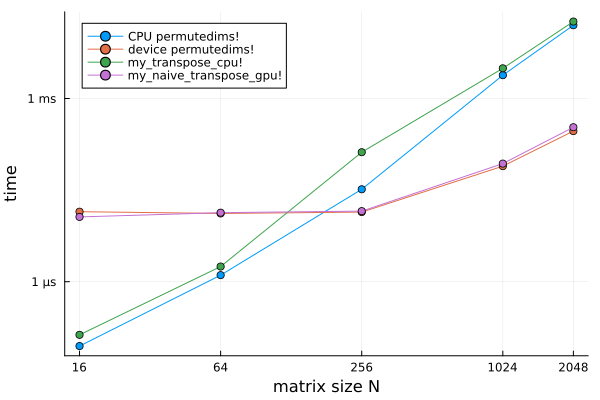

In [48]:
sizes = [16, 64, 256, 1024, 2048]
t_cpu_perm = Float64[]
t_dev_perm = Float64[]
t_my_transpose_cpu, t_my_naive_transpose_gpu = Float64[], Float64[]
for n in sizes
    X = rand(Float32, n, n)
    XT = similar(X)
    XT_loop = zeros(Float32, n, n)
    push!(t_cpu_perm, @belapsed permutedims!($XT, $X, (2, 1)))
    push!(t_my_transpose_cpu, @belapsed my_transpose_cpu!($XT_loop, $X))
    DX = allocate(Backend, Float32, n, n)
    copyto!(DX, X)
    DXT = KernelAbstractions.zeros(Backend, Float32, n, n)
    push!(t_dev_perm, @belapsed begin
        permutedims!($DXT, $DX, (2, 1))
        KernelAbstractions.synchronize($Backend)
    end)
    w = min(32, n)
    my_naive_gpu! = my_naive_transpose_gpu_kernel!(Backend, (w, w))
    DXT_naive = KernelAbstractions.zeros(Backend, Float32, n, n)
    push!(t_my_naive_transpose_gpu, @belapsed begin
        $my_naive_gpu!($DXT_naive, $DX; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

tlabel(v) = begin
    x, u = v < 1e-6 ? (v * 1e9, "ns") : v < 1e-3 ? (v * 1e6, "µs") : v < 1 ? (v * 1e3, "ms") : (v, "s")
    r = round(x; sigdigits = 2)
    string(isinteger(r) ? Int(r) : r, " ", u)
end

plt_transpose = Plots.plot(sizes, [t_cpu_perm t_dev_perm t_my_transpose_cpu t_my_naive_transpose_gpu];
    label = ["CPU permutedims!" "device permutedims!" "my_transpose_cpu!" "my_naive_transpose_gpu!"],
    xlabel = "matrix size N", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)
plt_transpose

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.1.4).** The cell above builds `plt_transpose` with CPU and device `permutedims!`, CPU `my_transpose_cpu!`, and `my_naive_transpose_gpu!`.

1. For small `N`, why can device `permutedims!` sit on a flat floor where the time barely changes when you increase `N`? What fixed cost dominates before moving `N²` elements matters?
2. Why can CPU `permutedims!` beat the device call for small matrices, and why does the device library call usually pull ahead once `N` is large enough? What has to be amortized for the device to win?
3. Will CPU and device `permutedims!` cross over at the same `N` on every machine or GPU? What varies between students’ plots?

</div>

<div style="border-left: 4px solid #2f9e44; background: rgba(47, 158, 68, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Answer (2.1.4).**

1. Device `permutedims!` pays **kernel launch and synchronization** (and any library setup) on every timed call. When `N` is tiny, the actual permute moves negligible data, so the curve stays on a launch floor and barely tracks `N`.
2. On the CPU there is no GPU launch; small problems stay on the host with low overhead. On the device, the same call must amortize that fixed cost over **Θ(`N²`)** memory traffic and parallel work. Once `N` is large enough on *your* plot, bulk movement on the GPU wins; the exact crossover is not universal.
3. **No.** Launch latency, memory bandwidth, CPU speed, backend (`DEV`), driver, and even whether arrays already live on the device all shift the curves. Compare trends (floor, then rise, then which curve is above) rather than a single magic `N`.

</div>


<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.1.3).** The kernel keeps the input in `@Const(A)` and writes a separate `AT`. Suppose instead every work item executed `A[j, i] = A[i, j]` on **one** device array `DA` (same buffer for input and output, no `@Const`).

1. For `i ≠ j`, work item `(i, j)` reads `A[i, j]` and writes `A[j, i]`. Which other work item also reads or writes those two locations?
2. Can `(i, j)` still read the original `A[i, j]` if `(j, i)` runs first? How is that related to the global race in the GPU introduction?
3. Why does the version above use `DAT` and `@Const(DA)`?

</div>

<div style="border-left: 4px solid #2f9e44; background: rgba(47, 158, 68, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Answer (2.1.3).**

1. Work item `(j, i)` — it touches the same two matrix entries in the opposite order.
2. Not reliably. If `(j, i)` runs first and writes `A[j, i]` before `(i, j)` reads, `(i, j)` may see the updated value instead of the original — a global race like the sum kernel in the GPU introduction.
3. `DAT` is a separate output buffer and `@Const(DA)` keeps the input read-only so work items do not overwrite data other work items still need to read.

</div>


## 2.2. Matrix multiplication

### 2.2.1. On the CPU

Dense matrix multiplication is the core of most dense linear algebra and the standard benchmark for floating-point throughput.

The textbook triple loop is in `my_matmul_cpu!` below (same `my_*` naming as §2.1); you will port its inner product to the device in Exercise 4 as `my_naive_matmul_gpu_kernel!`.

In [49]:
function my_matmul_cpu!(C, A, B)
    for i in 1:size(C, 1)
        for j in 1:size(C, 2)
            C[i, j] = zero(eltype(C))
            for k in 1:size(A, 2)
                C[i, j] += A[i, k] * B[k, j]
            end
        end
    end
end

my_matmul_cpu! (generic function with 1 method)

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 2: CPU matrix multiplication

Run the triple loop on `A` and `B` and compare the result with Julia's `*`.

Write one line of code at the `# TODO`. A solution is in `proposed-solution/exercise_2_cpu_matmul.ipynb`.

</div>

In [50]:
my_matmul_cpu!(C, A, B)

isapprox(C, A * B)

true

### 2.2.2. On the device

Copy `B` and allocate `DC`. Matrix multiplication on device arrays calls the vendor library (cuBLAS under CUDA, rocBLAS under ROCm, Metal on Apple; OpenBLAS when `DEV = :CPU`), unlike elementwise `+`, which launches a generated kernel.

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 3: Device library matrix multiplication

Copy `B` to the device, allocate `DC`, and multiply with `DA * DB`. Check against the CPU answer.

Write one line of code at each `# TODO`. A solution is in `proposed-solution/exercise_3_device_matmul.ipynb`.

</div>

In [51]:
DB = allocate(Backend, Float32, matrix_size, matrix_size)
copyto!(DB, B)
DC = KernelAbstractions.zeros(Backend, Float32, matrix_size, matrix_size)


1024×1024 CuArray{Float32, 2, CUDACore.DeviceMemory}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 ⋮                        ⋮              ⋱                 ⋮              
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.

In [52]:
DC = DA * DB

isapprox(Array(DC), A * B)

true

### 2.2.3. Naive matrix multiplication

These kernels do not call the library. Each work item writes one element. Transpose was the worked example in section 2.1; here you write the matrix multiplication kernel in the same style.

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 4: Naive matrix multiplication

Write `my_naive_matmul_gpu_kernel!` with one work item per element of `C`. Work item `(row, col)` computes the dot product of row `row` of `A` and column `col` of `B`. This is the innermost loop of the CPU `my_matmul_cpu!`; the two outer loops are replaced by the work items.

Write one line at each `# TODO`. The second cell clears `DC`; synchronize and the correctness check are already filled in. It should print `true`. A solution is in `proposed-solution/exercise_4_naive_matmul.ipynb`.

</div>

In [53]:
@kernel function my_naive_matmul_gpu_kernel!(C, @Const(A), @Const(B))
    row, col = @index(Global, NTuple)

    acc = zero(eltype(C))

    for k in 1:size(A, 2)
        @inbounds acc += A[row, k] * B[k, col]
    end

    @inbounds C[row, col] = acc
end

my_naive_matmul_gpu_kernel! (generic function with 4 methods)

In [54]:
fill!(DC, 0.0f0)
kernel! = my_naive_matmul_gpu_kernel!(Backend, (32, 32))
kernel!(DC, DA, DB, ndrange=size(DC))
KernelAbstractions.synchronize(Backend)

isapprox(Array(DC), A * B)

true

### 2.2.4. Timing

We now compare CPU and device `*` at `matrix_size` and over `sizes`. Device timings wait until the call has finished, as in the GPU introduction.

In [55]:
@benchmark my_matmul_cpu!($C, $A, $B)

BenchmarkTools.Trial: 2 samples with 1 evaluation per sample.
 Range (min … max):  2.901 s …  2.908 s  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     2.904 s             ┊ GC (median):    0.00%
 Time  (mean ± σ):   2.904 s ± 4.938 ms  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █                                                      █  
  █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁█ ▁
  2.9 s         Histogram: frequency by time        2.91 s <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [56]:
@benchmark A * B

BenchmarkTools.Trial: 749 samples with 1 evaluation per sample.
 Range (min … max):  3.981 ms … 44.473 ms  ┊ GC (min … max): 0.00% … 87.22%
 Time  (median):     5.871 ms              ┊ GC (median):    0.00%
 Time  (mean ± σ):   6.673 ms ±  3.165 ms  ┊ GC (mean ± σ):  9.30% ± 14.63%

       ▂▂▄▄▄▇█▇▇▅▃ ▂                   ▁     ▁▁               
  ▆▄▄▇▅██████████████▇▇▇▇▆▆▄▄▄▁▅▄▄▁▅▄▆▆█▆▇▇██████▆▇▅▄▄▄▄▁▅▁▄ █
  3.98 ms      Histogram: log(frequency) by time     12.9 ms <

 Memory estimate: 4.00 MiB, allocs estimate: 3.

We compare your kernel with the library's `DA * DB`. Both benchmarks include `synchronize`, so they measure the time until the result is available:

In [57]:
@benchmark begin
    DA * DB
    KernelAbstractions.synchronize(Backend)
end

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  306.600 μs …   6.817 ms  ┊ GC (min … max): 0.00% … 54.55%
 Time  (median):     401.800 μs               ┊ GC (median):    0.00%
 Time  (mean ± σ):   432.308 μs ± 262.292 μs  ┊ GC (mean ± σ):  0.79% ±  1.70%

       ▄▆▄▄▇▇█▇▅▃▁                                               
  ▂▂▃▄▇█████████████▇▆▆▅▅▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▂ ▄
  307 μs           Histogram: frequency by time          794 μs <

 Memory estimate: 1.14 KiB, allocs estimate: 32.

In [58]:
@benchmark begin
    kernel!(DC, DA, DB, ndrange=size(DC))
    KernelAbstractions.synchronize(Backend)
end

BenchmarkTools.Trial: 1893 samples with 1 evaluation per sample.
 Range (min … max):  2.318 ms …   7.943 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     2.535 ms               ┊ GC (median):    0.00%
 Time  (mean ± σ):   2.640 ms ± 467.949 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

   ▃▆▇█▇▅▃▂▂▃ ▁                                               ▁
  ██████████████▇▄▄▁▄▁▄▁▁▁▁▁▁▄▁▁▄▄▁▁▁▁▁▁▁▄▁▁▁▄▄▁▄▆▁▄▆▅▆▇▅▆▄▅▇ █
  2.32 ms      Histogram: log(frequency) by time      5.04 ms <

 Memory estimate: 1.17 KiB, allocs estimate: 37.

One timing at a single `N` hides how the cost grows. OpenBLAS, the library `*` dispatches to, is much faster than the triple loop: it blocks for the cache hierarchy, vectorizes with SIMD instructions, and uses all cores. The next cell times CPU and device `*`, the triple loop, and the naive matmul kernel over `sizes`, and builds `plt_matmul`.


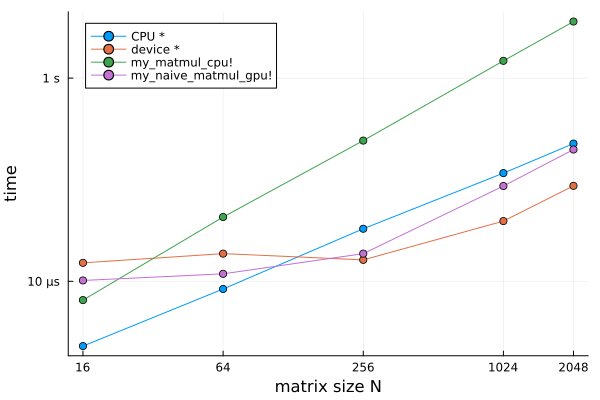

In [59]:
t_cpu_mul = Float64[]
t_dev_mul = Float64[]
t_my_matmul_cpu, t_my_naive_matmul_gpu = Float64[], Float64[]
for n in sizes
    X, Y = rand(Float32, n, n), rand(Float32, n, n)
    Z = zeros(Float32, n, n)
    push!(t_cpu_mul, @belapsed $X * $Y)
    push!(t_my_matmul_cpu, @belapsed my_matmul_cpu!($Z, $X, $Y))
    DX = allocate(Backend, Float32, n, n)
    copyto!(DX, X)
    DY = allocate(Backend, Float32, n, n)
    copyto!(DY, Y)
    push!(t_dev_mul, @belapsed begin
        $DX * $DY
        KernelAbstractions.synchronize($Backend)
    end)
    DZ = KernelAbstractions.zeros(Backend, Float32, n, n)
    w = min(32, n)
    k! = my_naive_matmul_gpu_kernel!(Backend, (w, w))
    push!(t_my_naive_matmul_gpu, @belapsed begin
        $k!($DZ, $DX, $DY; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

plt_matmul = Plots.plot(sizes, [t_cpu_mul t_dev_mul t_my_matmul_cpu t_my_naive_matmul_gpu];
    label = ["CPU *" "device *" "my_matmul_cpu!" "my_naive_matmul_gpu!"],
    xlabel = "matrix size N", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)
plt_matmul


<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.2.4).** The cell above builds `plt_matmul` over several matrix sizes.

1. For small `N`, why can the device `*` and naive kernel curves sit on a flat floor that barely changes when you increase `N`? What fixed cost dominates before the multiply itself matters?
2. As `N` grows, why do those curves rise above the floor? How does the work of matrix multiplication scale with `N`, and when does that work dominate the launch cost?
3. On a GPU backend, why is vendor `*` (`DA * DB`) usually much faster than the naive kernel at large `N`? If you set `DEV = :CPU`, what do the two `*` curves both measure?

</div>

<div style="border-left: 4px solid #2f9e44; background: rgba(47, 158, 68, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Answer (2.2.4).**

1. Each device call pays **kernel launch and synchronization** overhead before useful work runs. For tiny matrices the `O(N³)` multiply is negligible, so device `*` and the naive kernel sit on a similar floor and time barely tracks `N`.
2. Matrix multiplication does **Θ(`N³`)** multiply-adds and moves **Θ(`N²`)** data; as `N` increases those costs grow until they dominate the fixed launch cost and the curves climb on the log plot.
3. On the GPU, `DA * DB` calls a **vendor GEMM** (cuBLAS, rocBLAS, Metal, …) with cache-aware blocking, SIMD or wide loads, and often tensor cores. The naive kernel repeats global memory traffic and lacks that tuning. With `DEV = :CPU`, both `*` curves time **OpenBLAS** on the host (CPU `*` and device `*` use the same host arrays and the same library).

</div>


## 2.4. Tiled kernels

### 2.4.1. Shared memory

The library is much faster than one work item per output element. In the naive matrix multiplication kernel every work item reads a full row of `DA` and a full column of `DB` from global memory, although neighboring work items need largely the same values. Libraries tile the computation instead: each workgroup loads blocks of `DA` and `DB` into shared memory once and reuses them. On NVIDIA GPUs they also use tensor cores. Shared memory (`@localmem`) is a scratchpad private to one workgroup. A work item can read a value stored there by another work item of the same workgroup. The tiled kernels keep a tile in that scratchpad: the transpose so the write is coalesced, and the product so each loaded value is reused.

<div style="border-left: 4px solid #e03131; background: rgba(224, 49, 49, 0.08); padding: 0.6em 1.2em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Warning.** When different work items in one workgroup write and then read the same `@localmem` tile, you get a **race condition** like the global sum in the GPU introduction: the result depends on which work items run first. A work item can read a shared cell before a neighbor has stored it, or overwrite a tile while others still read it. Put a [`@synchronize()`](https://juliagpu.github.io/KernelAbstractions.jl/stable/api/#KernelAbstractions.@synchronize) between those phases so every load finishes before any read (see the [KernelAbstractions manual](https://juliagpu.github.io/KernelAbstractions.jl/stable/kernels/#Local-memory,-synchronization,-and-private-memory)). Use `@synchronize()` again before reloading the tile in multi-step kernels (Exercise 5). `@synchronize()` orders work items inside one workgroup only; `KernelAbstractions.synchronize(Backend)` makes the host wait for the device.

</div>

Each workgroup of `TILE_DIM × TILE_DIM` work items owns one tile. With many workgroups, each work item also needs to know which tile it belongs to:

| Construct | Meaning |
|---|---|
| `@index(Group, NTuple)` | index of the workgroup, `(gi, gj)` |
| `@index(Local, NTuple)` | index within the workgroup, `(i, j)` |

Work item `(i, j)` of workgroup `(gi, gj)` handles row `(gi - 1) * TILE_DIM + i` and column `(gj - 1) * TILE_DIM + j`, the same pair `@index(Global, NTuple)` would return.


### 2.4.2. Transpose

In the **load** phase, work item `(i, j)` reads global `A` and **writes shared `tile[i, j]`** (neighboring work items hit neighboring addresses in `A`, so the load is coalesced). That is only half of the tile: work item `(j, i)` **writes `tile[j, i]`**, a different shared cell, from its own global read. 

After **`@synchronize()`**, the **store** phase swaps roles in shared memory: `(i, j)` **reads `tile[j, i]`**—which only `(j, i)` wrote—and writes that value to global `AT` at the transposed tile position. Symmetrically, `(j, i)` reads `tile[i, j]`. Without the barrier, `(i, j)` can read `tile[j, i]` before `(j, i)` has finished storing it. 


In [60]:
const TILE_DIM = 16

@kernel unsafe_indices=true function my_tiled_transpose_gpu_kernel!(AT, @Const(A))
    gi, gj = @index(Group, NTuple)
    i, j = @index(Local, NTuple)
    N = @uniform @groupsize()[1]

    # (i,j) writes tile[i,j] then reads tile[j,i] (written by work item (j,i)); +1 row reduces bank conflicts on that read
    tile = @localmem eltype(A) (N + 1, N)

    I = (gi - 1) * N + i
    J = (gj - 1) * N + j
    @inbounds tile[i, j] = A[I, J]   # load phase: each work item fills one slot of tile

    @synchronize()   # wait until every tile[i,j] and tile[j,i] is written

    I = (gj - 1) * N + i
    J = (gi - 1) * N + j
    @inbounds AT[I, J] = tile[j, i]   # store phase: (i,j) reads the slot (j,i) filled
end

my_tiled_transpose_gpu_kernel! (generic function with 4 methods)

In [61]:
fill!(DAT, 0.0f0)

my_tiled_transpose_gpu! = my_tiled_transpose_gpu_kernel!(Backend, (TILE_DIM, TILE_DIM))
my_tiled_transpose_gpu!(DAT, DA, ndrange=size(DA))
KernelAbstractions.synchronize(Backend)

Array(DAT) == transpose(A)

true

The tiled transpose is added to `plt_transpose`. The library, `my_transpose_cpu!`, and `my_naive_transpose_gpu_kernel!` curves from section 2.1.4 are already on that figure.

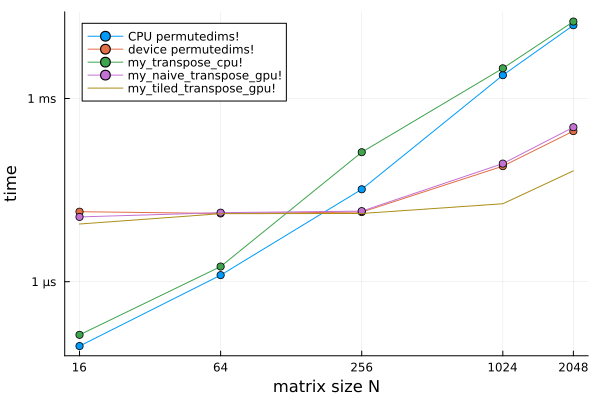

In [62]:
t_my_tiled_transpose_gpu = Float64[]
for n in sizes
    X = rand(Float32, n, n)
    DX = copyto!(allocate(Backend, Float32, n, n), X)
    DXT = KernelAbstractions.zeros(Backend, Float32, n, n)
    kt! = my_tiled_transpose_gpu_kernel!(Backend, (TILE_DIM, TILE_DIM))
    push!(t_my_tiled_transpose_gpu, @belapsed begin
        $kt!($DXT, $DX; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot!(plt_transpose, sizes, t_my_tiled_transpose_gpu; label = "my_tiled_transpose_gpu!")
plt_transpose

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.4.2).** Section 2.1.4 plots CPU and device `permutedims!`, CPU `my_transpose_cpu!`, `my_naive_transpose_gpu!`, and (after the cell above) `my_tiled_transpose_gpu!`.

1. For small `N`, why do the naive and tiled **device** kernels often take **similar** times that barely change when you increase `N`? What fixed cost dominates before the matrix is large enough for the transpose itself to matter?
2. As `N` grows, when do the device kernels typically become faster than CPU `my_transpose_cpu!`? When does `my_tiled_transpose_gpu!` become faster than `my_naive_transpose_gpu!`, and **why** does tiling help more as the matrix gets larger?
3. Why can device `permutedims!` lose to the CPU version for small `N`? When does the device library call usually pull ahead, and **why** can a hand-written tiled kernel eventually compete with or beat the vendor library at large `N`?

</div>

<div style="border-left: 4px solid #2f9e44; background: rgba(47, 158, 68, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Answer (2.4.2).**

1. **Kernel launch and synchronization** dominate: each device call pays a roughly fixed overhead before any element is moved. For tiny matrices the actual transpose work is negligible, so naive and tiled kernels sit on the same launch floor and the time barely tracks `N`. CPU `my_transpose_cpu!` avoids that launch cost and is often faster in this regime.
2. Once `N` is large enough, work and memory traffic grow (roughly like `N²`) and the curves rise above the floor; the GPU’s parallelism then beats the single-threaded CPU loop. The tiled kernel loads a block into shared memory and writes coalesced output, while the naive kernel does strided global reads and writes—so bandwidth waste shrinks with tiling and the tiled curve grows more slowly; the gap widens as `N` increases.
3. Small problems on the device still pay launch (and any setup) without enough parallel work to amortize it, so CPU `permutedims!` can win. For larger `N`, bulk data movement on the device favors the vendor library. At the largest sizes on the plot, a kernel tailored to this access pattern (shared-memory tile + coalesced write) can match or beat a generic `permutedims!` path because every global access is arranged for the transpose, not a general axis permutation.

</div>


### 2.4.3. Matrix multiplication

<img src="../img/matmul.svg" alt="Tiles of a matrix product. One output tile is the sum, over the inner index, of a tile of each factor." style="max-width:560px; width:100%; height:auto; display:block;" />

Each workgroup owns one tile of `C`. The workgroup walks the inner dimension in steps `t`: load matching tiles of `A` and `B` into shared `tileA` and `tileB`, `@synchronize`, update each work item's running sum from those tiles, then `@synchronize` again before the next pair overwrites shared memory. Exercise 5 implements that loop.


<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 5: Tiled matrix multiplication

Write `my_tiled_matmul_gpu_kernel!` with shared tiles `tileA` and `tileB`. The skeleton already computes `row`, `col`, and the loop over `t`. Write one line at each `# TODO`. The second cell clears `DC`; synchronize and the correctness check are already filled in. A solution is in `proposed-solution/exercise_5_tiled_matmul.ipynb`.

</div>


In [63]:
@kernel function my_tiled_matmul_gpu_kernel!(C, @Const(A), @Const(B))
    gi, gj = @index(Group, NTuple)
    i, j = @index(Local, NTuple)

    tileA = @localmem eltype(C) (TILE_DIM, TILE_DIM)
    tileB = @localmem eltype(C) (TILE_DIM, TILE_DIM)

    row = (gi - 1) * TILE_DIM + i
    col = (gj - 1) * TILE_DIM + j
    acc = zero(eltype(C))

    for t in 0:(size(A, 2) ÷ TILE_DIM - 1)
        @inbounds tileA[i, j] = A[row, t * TILE_DIM + j]
        @inbounds tileB[i, j] = B[t * TILE_DIM + i, col]

        @synchronize()

        for k in 1:TILE_DIM
            @inbounds acc += tileA[i, k] * tileB[k, j]
        end

        @synchronize()
    end

    @inbounds C[row, col] = acc
end

my_tiled_matmul_gpu_kernel! (generic function with 4 methods)

In [64]:
fill!(DC, 0.0f0)
my_tiled_matmul_gpu! = my_tiled_matmul_gpu_kernel!(Backend, (TILE_DIM, TILE_DIM))
my_tiled_matmul_gpu!(DC, DA, DB, ndrange=size(DC))
KernelAbstractions.synchronize(Backend)

isapprox(Array(DC), A * B)

true

We time your tiled kernel for comparison with the naive kernel and the library in section 2.2:

In [65]:
@benchmark begin
    my_tiled_matmul_gpu!(DC, DA, DB, ndrange=size(DC))
    KernelAbstractions.synchronize(Backend)
end

BenchmarkTools.Trial: 2594 samples with 1 evaluation per sample.
 Range (min … max):  1.696 ms …   2.703 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     1.891 ms               ┊ GC (median):    0.00%
 Time  (mean ± σ):   1.925 ms ± 160.871 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

   ▂▁▃▂▂▃▅▇▇▇▅▅▇▇▇█▇▅▂ ▁▁                ▁ ▁   ▁              ▂
  ▇███████████████████▇██▆▆██▅▇▇▇▅▇▆▇█▆▆▇███▇█▆███▇▇█▆▇▇▇▇▇▅▆ █
  1.7 ms       Histogram: log(frequency) by time       2.5 ms <

 Memory estimate: 1.17 KiB, allocs estimate: 37.

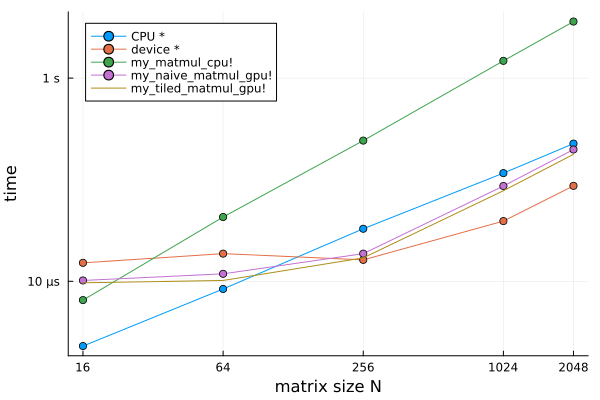

In [66]:
t_dev_tiled = Float64[]
for n in sizes
    X, Y = rand(Float32, n, n), rand(Float32, n, n)
    DX = copyto!(allocate(Backend, Float32, n, n), X)
    DY = copyto!(allocate(Backend, Float32, n, n), Y)
    DZ = KernelAbstractions.zeros(Backend, Float32, n, n)
    k! = my_tiled_matmul_gpu_kernel!(Backend, (TILE_DIM, TILE_DIM))
    push!(t_dev_tiled, @belapsed begin
        $k!($DZ, $DX, $DY; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot!(plt_matmul, sizes, t_dev_tiled; label = "my_tiled_matmul_gpu!")
plt_matmul

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.4.3).** Section 2.2.4 plots CPU and device `*`, the CPU triple loop, the naive matmul kernel, and (after the cell above) your tiled matmul kernel.

1. In the naive kernel, each work item computes one entry of `C` but loads a full row of `A` and a full column of `B` from global memory. Why is global bandwidth often the limit, and why do neighboring work items repeat much of the same traffic?
2. Inside the loop over tile index `t`, why do you need `@synchronize()` after loading `tileA` and `tileB`, and again before the next load step? What goes wrong if a work item reads shared memory while a neighbor is still writing it?
3. For small `N`, why can the naive and tiled device kernels sit on a similar time floor? As `N` grows, why does tiling pull ahead of the naive kernel, and why does `DA * DB` (the vendor library) usually stay faster than both custom kernels?

</div>

<div style="border-left: 4px solid #2f9e44; background: rgba(47, 158, 68, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Answer (2.4.3).**

1. The dot product for one output needs `O(N)` memory accesses but only `O(N)` multiply-adds, so performance is often **memory-bandwidth** limited long before compute is saturated. Work items that share a row or column load overlapping regions of `A` and `B` from **global** memory independently, so the same values are fetched many times across the grid.
2. `@localmem` is shared by the whole workgroup. Without a barrier after the load phase, a work item can multiply using `tileA`/`tileB` entries that a neighbor has not stored yet; without a barrier before the next load, a work item can overwrite a tile while others still read it — the same **race** pattern as in the GPU introduction, but in shared memory.
3. Small matrices pay mostly **launch and synchronization**; both custom kernels hit a similar floor. As `N` grows, the tiled kernel loads each block of `A` and `B` into shared memory once per step and reuses it across the workgroup, while the naive kernel still streams full rows and columns from global memory, so tiling wins by cutting redundant traffic. `DA * DB` stays ahead because the vendor library adds autotuned blocking, **register blocking**, vectorized or wide loads, and (on NVIDIA) **tensor cores** — see [`performant_matmul.jl`](https://github.com/JuliaGPU/KernelAbstractions.jl/blob/main/examples/performant_matmul.jl) for a more complete tiled example.

</div>


# 3. Summary

- Naive kernels with one work item per output element: transpose and matrix multiplication
- Global memory access: coalescing and data reuse
- Shared memory (`@localmem`), and a `@synchronize` so that a write and a later read do not overlap
- Tiled kernels: a coalesced transpose, and a matrix multiplication that reuses its tiles

## 3.1. Further exploration

These are optional and not graded.

1. **Bank conflicts and padding.** `my_tiled_transpose_gpu_kernel!` already pads the tile to `(N + 1, N)` for the transposed shared-memory read. Drop the `+ 1`, compare timings, and relate the difference to bank conflicts.
2. **Tile size.** Compare `TILE_DIM` = 8, 16, and 32, and explain the result in terms of occupancy and shared-memory use.
3. **Register blocking.** Let each work item compute a small block of `C` (for example 4×1 or 4×4 elements), keeping partial sums and reused values of `A` and `B` in registers. Too many registers per work item lowers occupancy.
4. **Vendor libraries.** Compare your fastest kernel with `DA * DB` (cuBLAS, rocBLAS, or Metal Performance Shaders). Read the performance guide for your backend (for example the CUDA C++ Best Practices Guide) and identify which recommendations your kernel does not yet follow.

Time a variant the same way: push the times into an array and add a curve with `Plots.plot!(plt_matmul, ...)`.